In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/ADNIMERGE2/research_dataset/clean_cn_amyloid_dataset.csv"
)

In [3]:
df.head()

,RID,amyloid_label,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q,APOE4,AGE,SEX,PTEDUCAT
0,6001,0,0.386,0.0973,27.5,175.4,0,73.051335,0,14.0
1,6005,0,0.105,0.0843,9.8,181.3,1,68.334018,0,20.0
2,6015,0,1.291,0.0839,34.4,304.4,0,68.396988,1,14.0
3,6009,0,0.111,0.0857,12.2,100.8,1,68.369610,1,16.0
4,6044,1,0.627,0.0885,26.5,209.3,1,75.526352,0,18.0


# **Issues in Dataset**
```


1. PTEDUCAT column datatype should be changed from float to int.✅

2. RID column should not be used as a machine learning feature.

3. Feature scales are very different and scaling will be required.

4. pT217_F distribution is right-skewed.

5. NfL_Q distribution is right-skewed.

6. GFAP_Q distribution is heavily right-skewed.

7. Dataset has mild class imbalance between A+ and A- classes.

8. Biomarker distributions are non-normal.

9. No missing values found in final dataset.

10. No severe multicollinearity detected between features.


In [4]:
df.describe()

,RID,amyloid_label,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q,APOE4,AGE,SEX,PTEDUCAT
count,238.000000,238.000000,238.000000,238.000000,238.000000,238.000000,238.000000,238.000000,238.000000,238.000000
mean,6491.714286,0.247899,0.153420,0.091711,16.839496,138.514286,0.348739,70.231763,0.365546,16.739496
std,330.869591,0.432703,0.191283,0.010557,7.565943,69.906314,0.477576,6.826679,0.482598,2.122661
min,6001.000000,0.000000,0.030000,0.061500,5.100000,33.100000,0.000000,51.014374,0.000000,11.000000
25%,6228.250000,0.000000,0.071250,0.083825,11.500000,89.425000,0.000000,66.631075,0.000000,16.000000
50%,6416.500000,0.000000,0.104500,0.090900,15.150000,125.700000,0.000000,69.624914,0.000000,16.000000
75%,6800.750000,0.000000,0.152500,0.099475,20.150000,175.000000,1.000000,74.568789,1.000000,18.000000
max,7123.000000,1.000000,1.938000,0.132300,50.900000,430.700000,1.000000,91.137577,1.000000,20.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 238 entries, 0 to 237
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   RID            238 non-null    int64  
 1   amyloid_label  238 non-null    int64  
 2   pT217_F        238 non-null    float64
 3   AB42_AB40_F    238 non-null    float64
 4   NfL_Q          238 non-null    float64
 5   GFAP_Q         238 non-null    float64
 6   APOE4          238 non-null    int64  
 7   AGE            238 non-null    float64
 8   SEX            238 non-null    int64  
 9   PTEDUCAT       238 non-null    float64
dtypes: float64(6), int64(4)
memory usage: 18.7 KB


In [6]:
df.skew()

,0
RID,0.436536
amyloid_label,1.175112
pT217_F,5.490848
AB42_AB40_F,0.310920
NfL_Q,1.483225
GFAP_Q,1.353981
APOE4,0.638820
AGE,0.205574
SEX,0.561930
PTEDUCAT,-0.335133


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RID,238.0,6491.714286,330.869591,6001.000000,6228.250000,6416.500000,6800.750000,7123.000000
amyloid_label,238.0,0.247899,0.432703,0.000000,0.000000,0.000000,0.000000,1.000000
pT217_F,238.0,0.153420,0.191283,0.030000,0.071250,0.104500,0.152500,1.938000
AB42_AB40_F,238.0,0.091711,0.010557,0.061500,0.083825,0.090900,0.099475,0.132300
NfL_Q,238.0,16.839496,7.565943,5.100000,11.500000,15.150000,20.150000,50.900000
GFAP_Q,238.0,138.514286,69.906314,33.100000,89.425000,125.700000,175.000000,430.700000
APOE4,238.0,0.348739,0.477576,0.000000,0.000000,0.000000,1.000000,1.000000
AGE,238.0,70.231763,6.826679,51.014374,66.631075,69.624914,74.568789,91.137577
SEX,238.0,0.365546,0.482598,0.000000,0.000000,0.000000,1.000000,1.000000
PTEDUCAT,238.0,16.739496,2.122661,11.000000,16.000000,16.000000,18.000000,20.000000


array([[<Axes: title={'center': 'RID'}>,
        <Axes: title={'center': 'amyloid_label'}>,
        <Axes: title={'center': 'pT217_F'}>],
       [<Axes: title={'center': 'AB42_AB40_F'}>,
        <Axes: title={'center': 'NfL_Q'}>,
        <Axes: title={'center': 'GFAP_Q'}>],
       [<Axes: title={'center': 'APOE4'}>,
        <Axes: title={'center': 'AGE'}>, <Axes: title={'center': 'SEX'}>],
       [<Axes: title={'center': 'PTEDUCAT'}>, <Axes: >, <Axes: >]],
      dtype=object)

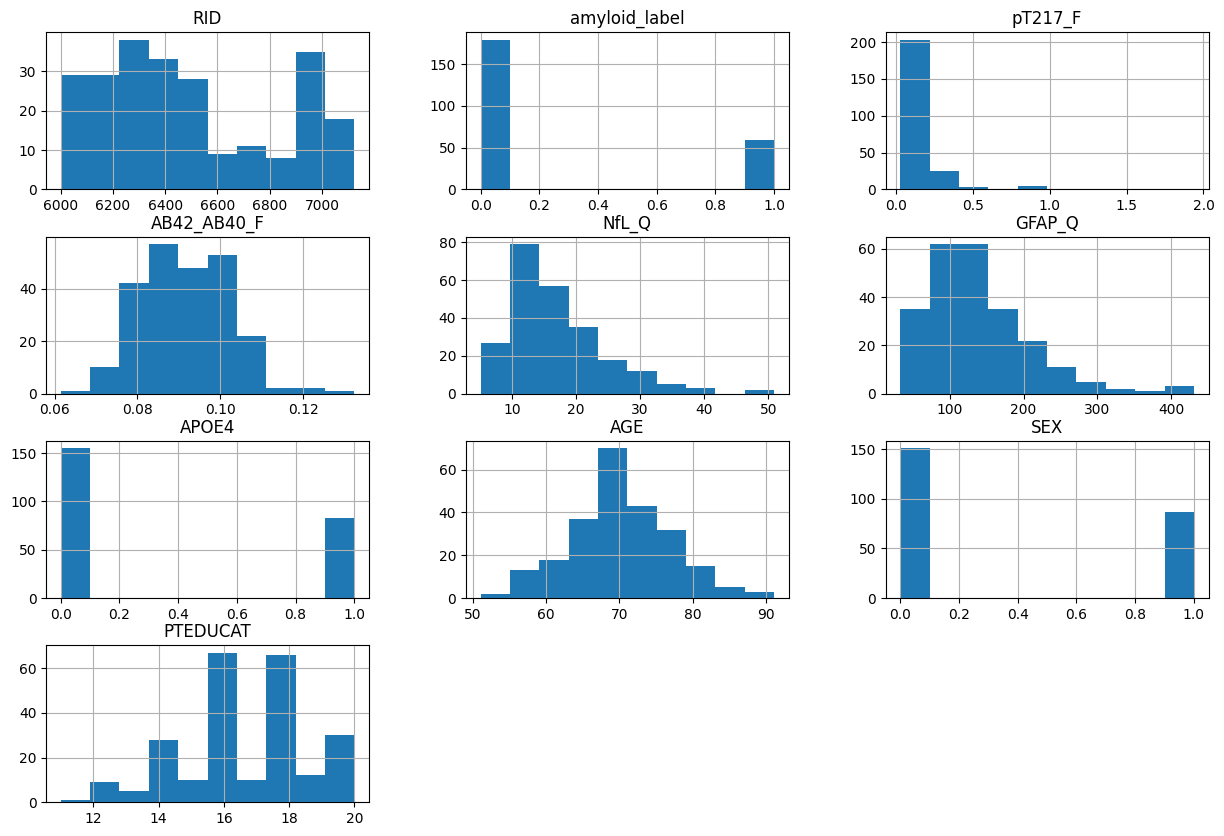

In [8]:
df.hist(figsize=(15,10))

In [9]:
df.corr(numeric_only=True)

,RID,amyloid_label,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q,APOE4,AGE,SEX,PTEDUCAT
RID,1.000000,-0.047778,-0.191067,0.029074,-0.298129,-0.032357,0.085307,-0.245276,0.003220,-0.122004
amyloid_label,-0.047778,1.000000,0.345593,-0.460444,0.218806,0.330308,0.294521,0.211917,-0.031667,0.010886
pT217_F,-0.191067,0.345593,1.000000,-0.030623,0.365132,0.319499,0.003747,0.209768,0.144960,0.002505
AB42_AB40_F,0.029074,-0.460444,-0.030623,1.000000,-0.175677,-0.271150,-0.305680,-0.154234,-0.034443,0.029921
NfL_Q,-0.298129,0.218806,0.365132,-0.175677,1.000000,0.582073,-0.107173,0.460299,0.035781,0.109781
GFAP_Q,-0.032357,0.330308,0.319499,-0.271150,0.582073,1.000000,0.033443,0.364068,-0.061177,-0.012119
APOE4,0.085307,0.294521,0.003747,-0.305680,-0.107173,0.033443,1.000000,-0.121414,-0.097767,-0.080657
AGE,-0.245276,0.211917,0.209768,-0.154234,0.460299,0.364068,-0.121414,1.000000,0.192955,0.119538
SEX,0.003220,-0.031667,0.144960,-0.034443,0.035781,-0.061177,-0.097767,0.192955,1.000000,0.093351
PTEDUCAT,-0.122004,0.010886,0.002505,0.029921,0.109781,-0.012119,-0.080657,0.119538,0.093351,1.000000


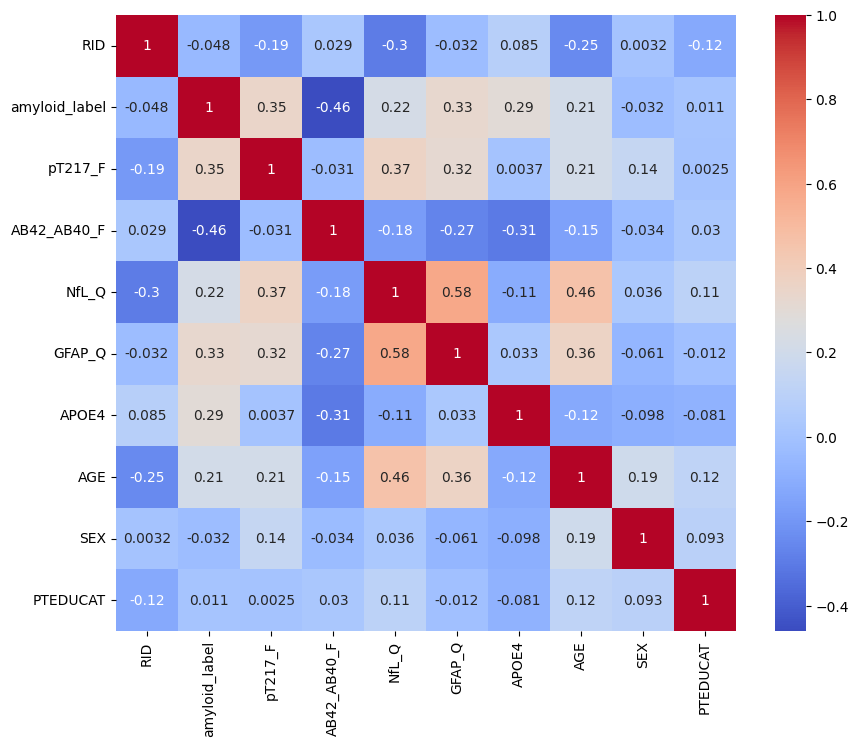

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.show()

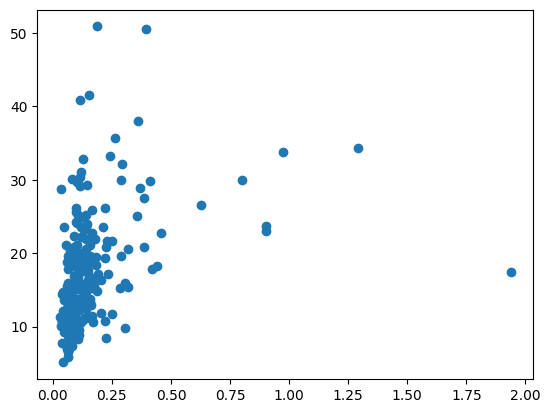

In [11]:
import matplotlib.pyplot as plt
plt.scatter(df['pT217_F'], df['NfL_Q'])

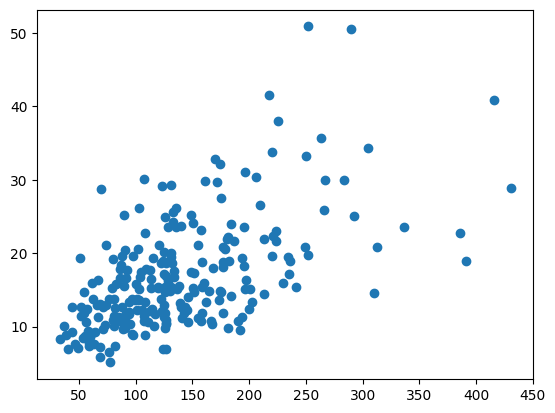

In [12]:
plt.scatter(df['GFAP_Q'], df['NfL_Q'])

In [13]:
df["PTEDUCAT"] = df["PTEDUCAT"].astype(int)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 238 entries, 0 to 237
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   RID            238 non-null    int64  
 1   amyloid_label  238 non-null    int64  
 2   pT217_F        238 non-null    float64
 3   AB42_AB40_F    238 non-null    float64
 4   NfL_Q          238 non-null    float64
 5   GFAP_Q         238 non-null    float64
 6   APOE4          238 non-null    int64  
 7   AGE            238 non-null    float64
 8   SEX            238 non-null    int64  
 9   PTEDUCAT       238 non-null    int64  
dtypes: float64(5), int64(5)
memory usage: 18.7 KB


In [15]:
X = df.drop(columns=["RID", "amyloid_label"])

y = df["amyloid_label"]

print(X.shape)
print(y.shape)

(238, 8)
(238,)


In [16]:
y

,amyloid_label
0,0
1,0
2,0
3,0
4,1
...,...
233,0
234,1
235,0
236,1


In [17]:
from sklearn.model_selection import train_test_split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [19]:
print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

(190, 8)
(48, 8)
(190,)
(48,)


In [20]:
from sklearn.preprocessing import StandardScaler

In [21]:
scaler = StandardScaler()

In [22]:
X_train_scaled = scaler.fit_transform(X_train)

In [23]:
X_test_scaled = scaler.transform(X_test)

# EXPERIMENT 1
**Logistic Regression Baseline**

In [24]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression()

log_model.fit(X_train_scaled, y_train)

LogisticRegression()

In [25]:
y_pred_log = log_model.predict(X_test_scaled)

y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]

In [26]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred_log))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_log))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log))

print("\nROC-AUC Score:")
print(roc_auc_score(y_test, y_prob_log))

Accuracy: 0.8125

Confusion Matrix:
[[32  4]
 [ 5  7]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.89      0.88        36
           1       0.64      0.58      0.61        12

    accuracy                           0.81        48
   macro avg       0.75      0.74      0.74        48
weighted avg       0.81      0.81      0.81        48


ROC-AUC Score:
0.9074074074074074


In [28]:
import joblib

In [29]:
joblib.dump(log_model, "logistic_regression_model.pkl")

['logistic_regression_model.pkl']

In [30]:
joblib.dump(scaler, "standard_scaler.pkl")

['standard_scaler.pkl']

In [31]:
joblib.dump(log_model, "logistic_regression_model.pkl")

['logistic_regression_model.pkl']

Dataset shape: (238, 2)

Label distribution:
amyloid_label
0    179
1     59
Name: count, dtype: int64

Missing values:
pT217_F        0
AB42_AB40_F    0
dtype: int64

Train size: (190, 2)
Test size: (48, 2)

EXPERIMENT C — Janelidze Replication
Features: pT217_F + AB42_AB40_F only
AUC:      0.9005
Accuracy: 0.7917

Classification Report:
              precision    recall  f1-score   support

          A-       0.82      0.92      0.87        36
          A+       0.62      0.42      0.50        12

    accuracy                           0.79        48
   macro avg       0.72      0.67      0.68        48
weighted avg       0.78      0.79      0.78        48

Confusion Matrix:
[[33  3]
 [ 7  5]]

COMPARISON TO BENCHMARK
Janelidze 2021 AUC: 0.830 - 0.860
Your Model AUC:     0.9005
Result: BEATS Janelidze 2021 ✅


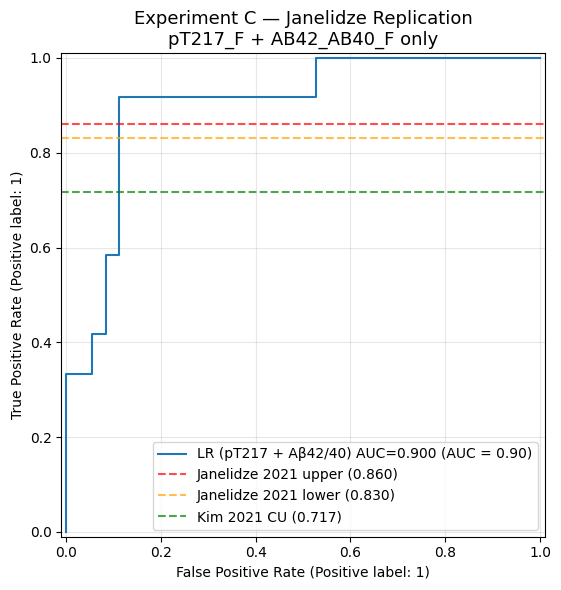


ROC curve saved!


In [27]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)
import matplotlib.pyplot as plt

# ── 1. Select only these 2 features ──
features_janelidze = ['pT217_F', 'AB42_AB40_F']
target = 'amyloid_label'

X = df[features_janelidze]
y = df[target]

print("Dataset shape:", X.shape)
print("\nLabel distribution:")
print(y.value_counts())
print("\nMissing values:")
print(X.isnull().sum())

# ── 2. Train test split ──
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTrain size:", X_train.shape)
print("Test size:", X_test.shape)

# ── 3. Scale features ──
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ── 4. Train Logistic Regression ──
lr = LogisticRegression(
    random_state=42,
    max_iter=1000
)
lr.fit(X_train_scaled, y_train)

# ── 5. Predictions ──
y_pred = lr.predict(X_test_scaled)
y_prob = lr.predict_proba(X_test_scaled)[:, 1]

# ── 6. Metrics ──
auc = roc_auc_score(y_test, y_prob)
acc = accuracy_score(y_test, y_pred)

print("\n" + "="*50)
print("EXPERIMENT C — Janelidze Replication")
print("Features: pT217_F + AB42_AB40_F only")
print("="*50)
print(f"AUC:      {auc:.4f}")
print(f"Accuracy: {acc:.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['A-', 'A+']
))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# ── 7. Compare to Janelidze 2021 ──
print("\n" + "="*50)
print("COMPARISON TO BENCHMARK")
print("="*50)
print(f"Janelidze 2021 AUC: 0.830 - 0.860")
print(f"Your Model AUC:     {auc:.4f}")
if auc > 0.860:
    print("Result: BEATS Janelidze 2021 ✅")
elif auc >= 0.830:
    print("Result: MATCHES Janelidze 2021 ✅")
else:
    print("Result: Below Janelidze 2021 ⚠️")

# ── 8. ROC Curve ──
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_estimator(
    lr, X_test_scaled, y_test,
    ax=ax,
    name=f'LR (pT217 + Aβ42/40) AUC={auc:.3f}'
)

# Add reference lines for benchmarks
ax.axhline(y=0.860, color='red',
           linestyle='--', alpha=0.7,
           label='Janelidze 2021 upper (0.860)')
ax.axhline(y=0.830, color='orange',
           linestyle='--', alpha=0.7,
           label='Janelidze 2021 lower (0.830)')
ax.axhline(y=0.717, color='green',
           linestyle='--', alpha=0.7,
           label='Kim 2021 CU (0.717)')

ax.set_title(
    'Experiment C — Janelidze Replication\n'
    'pT217_F + AB42_AB40_F only',
    fontsize=13
)
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('experiment_C_janelidze_replication.png',
            dpi=150)
plt.show()

print("\nROC curve saved!")

In [28]:
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE
from sklearn.metrics import roc_auc_score

# Method 1 — Class weights (easiest)
lr_balanced = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)
lr_balanced.fit(X_train_scaled, y_train)

y_prob_bal = lr_balanced.predict_proba(
    X_test_scaled)[:, 1]
y_pred_bal = lr_balanced.predict(X_test_scaled)

print("With class_weight=balanced:")
print(f"AUC: {roc_auc_score(y_test, y_prob_bal):.4f}")
print(classification_report(
    y_test, y_pred_bal,
    target_names=['A-', 'A+']))

# Method 2 — SMOTE
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(
    X_train_scaled, y_train)

print("\nAfter SMOTE:")
print(pd.Series(y_train_sm).value_counts())

lr_smote = LogisticRegression(
    random_state=42,
    max_iter=1000
)
lr_smote.fit(X_train_sm, y_train_sm)

y_prob_sm = lr_smote.predict_proba(
    X_test_scaled)[:, 1]
y_pred_sm = lr_smote.predict(X_test_scaled)

print("\nWith SMOTE:")
print(f"AUC: {roc_auc_score(y_test, y_prob_sm):.4f}")
print(classification_report(
    y_test, y_pred_sm,
    target_names=['A-', 'A+']))

With class_weight=balanced:
AUC: 0.9051
              precision    recall  f1-score   support

          A-       0.96      0.75      0.84        36
          A+       0.55      0.92      0.69        12

    accuracy                           0.79        48
   macro avg       0.76      0.83      0.77        48
weighted avg       0.86      0.79      0.80        48


After SMOTE:
amyloid_label
0    143
1    143
Name: count, dtype: int64

With SMOTE:
AUC: 0.9028
              precision    recall  f1-score   support

          A-       0.96      0.75      0.84        36
          A+       0.55      0.92      0.69        12

    accuracy                           0.79        48
   macro avg       0.76      0.83      0.77        48
weighted avg       0.86      0.79      0.80        48



In [29]:
from xgboost import XGBClassifier

# Calculate imbalance ratio
neg = sum(y_train == 0)
pos = sum(y_train == 1)
ratio = neg / pos
print(f"Scale pos weight: {ratio:.2f}")

xgb = XGBClassifier(
    scale_pos_weight=ratio,
    n_estimators=100,
    random_state=42,
    eval_metric='auc'
)
xgb.fit(X_train_scaled, y_train)

y_prob_xgb = xgb.predict_proba(
    X_test_scaled)[:, 1]
y_pred_xgb = xgb.predict(X_test_scaled)

print("\nXGBoost Results:")
print(f"AUC: {roc_auc_score(y_test, y_prob_xgb):.4f}")
print(classification_report(
    y_test, y_pred_xgb,
    target_names=['A-', 'A+']))

Scale pos weight: 3.04

XGBoost Results:
AUC: 0.8750
              precision    recall  f1-score   support

          A-       0.89      0.89      0.89        36
          A+       0.67      0.67      0.67        12

    accuracy                           0.83        48
   macro avg       0.78      0.78      0.78        48
weighted avg       0.83      0.83      0.83        48



In [30]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)
rf.fit(X_train_scaled, y_train)

y_prob_rf = rf.predict_proba(
    X_test_scaled)[:, 1]
y_pred_rf = rf.predict(X_test_scaled)

print("\nRandom Forest Results:")
print(f"AUC: {roc_auc_score(y_test, y_prob_rf):.4f}")
print(classification_report(
    y_test, y_pred_rf,
    target_names=['A-', 'A+']))


Random Forest Results:
AUC: 0.8576
              precision    recall  f1-score   support

          A-       0.82      0.92      0.87        36
          A+       0.62      0.42      0.50        12

    accuracy                           0.79        48
   macro avg       0.72      0.67      0.68        48
weighted avg       0.78      0.79      0.78        48



In [36]:
import joblib
import os

os.makedirs('saved_models', exist_ok=True)

joblib.dump(lr_balanced,
    'saved_models/LR_balanced_2feat.pkl')

joblib.dump(xgb,
    'saved_models/XGB_2feat.pkl')

joblib.dump(rf,
    'saved_models/RF_2feat.pkl')

joblib.dump(scaler,
    'saved_models/scaler_2feat.pkl')

print("3 models + scaler saved!")

3 models + scaler saved!


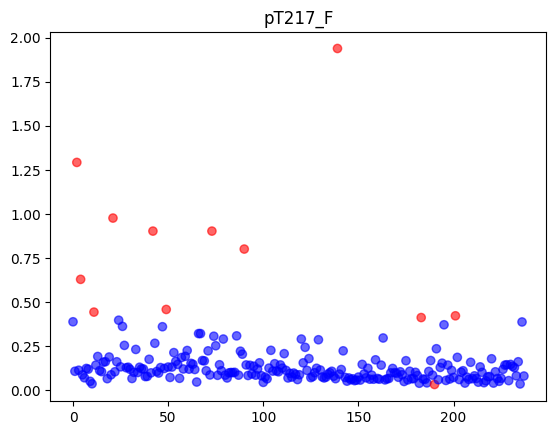

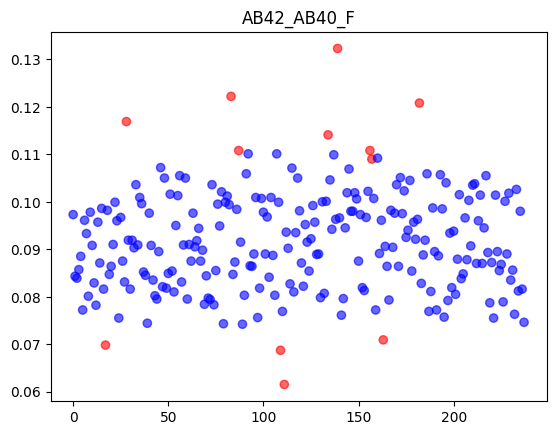

In [31]:
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

# Plot Column 1
c1_outliers = IsolationForest(contamination=0.05, random_state=42).fit_predict(df[['pT217_F']]) == -1
plt.scatter(df.index, df['pT217_F'], c=c1_outliers, cmap='bwr', alpha=0.6); plt.title('pT217_F'); plt.show()

# Plot Column 2
c2_outliers = IsolationForest(contamination=0.05, random_state=42).fit_predict(df[['AB42_AB40_F']]) == -1
plt.scatter(df.index, df['AB42_AB40_F'], c=c2_outliers, cmap='bwr', alpha=0.6); plt.title('AB42_AB40_F'); plt.show()


In [32]:
df[df["pT217_F"] > 0.8]

,RID,amyloid_label,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q,APOE4,AGE,SEX,PTEDUCAT
2,6015,0,1.291,0.0839,34.4,304.4,0,68.396988,1,14
21,6084,1,0.975,0.0910,33.8,220.4,0,78.866530,1,20
42,6199,1,0.901,0.0835,23.0,223.9,1,70.236824,1,16
73,6351,0,0.901,0.1036,23.7,140.0,0,74.422998,0,18
139,6437,1,1.938,0.1323,17.4,104.5,0,76.717317,1,16




# RobustScaler


In [33]:
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ─────────────────────────────────────
# 1. Robust Scaling
# ─────────────────────────────────────

robust_scaler = RobustScaler()

X_train_robust = robust_scaler.fit_transform(X_train)
X_test_robust = robust_scaler.transform(X_test)

# ─────────────────────────────────────
# 2. Logistic Regression
# ─────────────────────────────────────

lr_robust = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

lr_robust.fit(X_train_robust, y_train)

# ─────────────────────────────────────
# 3. Predictions
# ─────────────────────────────────────

y_pred_robust = lr_robust.predict(X_test_robust)

y_prob_robust = lr_robust.predict_proba(
    X_test_robust
)[:, 1]

# ─────────────────────────────────────
# 4. Evaluation
# ─────────────────────────────────────

print("="*50)
print("ROBUST SCALER + LOGISTIC REGRESSION")
print("="*50)

print(f"Accuracy: {accuracy_score(y_test, y_pred_robust):.4f}")

print(f"\nROC-AUC: {roc_auc_score(y_test, y_prob_robust):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_robust,
    target_names=['A-', 'A+']
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_robust))

ROBUST SCALER + LOGISTIC REGRESSION
Accuracy: 0.7917

ROC-AUC: 0.9097

Classification Report:
              precision    recall  f1-score   support

          A-       0.96      0.75      0.84        36
          A+       0.55      0.92      0.69        12

    accuracy                           0.79        48
   macro avg       0.76      0.83      0.77        48
weighted avg       0.86      0.79      0.80        48

Confusion Matrix:
[[27  9]
 [ 1 11]]


In [40]:
import joblib

In [41]:
joblib.dump(
    lr_robust,
    "robust_logistic_regression.pkl"
)

joblib.dump(
    robust_scaler,
    "robust_scaler.pkl"
)

['robust_scaler.pkl']

In [34]:
from lightgbm import LGBMClassifier

In [35]:
lgbm = LGBMClassifier(
    class_weight='balanced',
    random_state=42,
    n_estimators=100
)

In [ ]:
lgbm.fit(X_train, y_train)

[LightGBM] [Info] Number of positive: 47, number of negative: 143
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000156 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 120
[LightGBM] [Info] Number of data points in the train set: 190, number of used features: 2
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

In [45]:
y_pred_lgbm = lgbm.predict(X_test)

y_prob_lgbm = lgbm.predict_proba(X_test)[:, 1]

In [46]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("="*50)
print("LIGHTGBM RESULTS")
print("="*50)

print(f"Accuracy: {accuracy_score(y_test, y_pred_lgbm):.4f}")

print(f"\nROC-AUC: {roc_auc_score(y_test, y_prob_lgbm):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lgbm,
    target_names=['A-', 'A+']
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lgbm))

LIGHTGBM RESULTS
Accuracy: 0.8125

ROC-AUC: 0.8970

Classification Report:
              precision    recall  f1-score   support

          A-       0.89      0.86      0.87        36
          A+       0.62      0.67      0.64        12

    accuracy                           0.81        48
   macro avg       0.75      0.76      0.76        48
weighted avg       0.82      0.81      0.81        48

Confusion Matrix:
[[31  5]
 [ 4  8]]


# threshold optimization

In [47]:
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression

# Robust Scaling
robust_scaler = RobustScaler()

X_train_robust = robust_scaler.fit_transform(X_train)
X_test_robust = robust_scaler.transform(X_test)

# Logistic Regression
lr_robust = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

lr_robust.fit(X_train_robust, y_train)


LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [48]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ─────────────────────────────────────
# Predicted probabilities
# ─────────────────────────────────────

y_prob = lr_robust.predict_proba(
    X_test_robust
)[:, 1]

# ─────────────────────────────────────
# Threshold range
# ─────────────────────────────────────

thresholds = np.arange(0.30, 0.71, 0.05)

results = []

# ─────────────────────────────────────
# Evaluate thresholds
# ─────────────────────────────────────

for threshold in thresholds:

    y_pred_thresh = (
        y_prob >= threshold
    ).astype(int)

    acc = accuracy_score(
        y_test,
        y_pred_thresh
    )

    precision = precision_score(
        y_test,
        y_pred_thresh
    )

    recall = recall_score(
        y_test,
        y_pred_thresh
    )

    f1 = f1_score(
        y_test,
        y_pred_thresh
    )

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_thresh
    ).ravel()

    specificity = tn / (tn + fp)

    results.append([
        threshold,
        acc,
        precision,
        recall,
        specificity,
        f1,
        fp,
        fn
    ])

# ─────────────────────────────────────
# Results table
# ─────────────────────────────────────

results_df = pd.DataFrame(
    results,
    columns=[
        "Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "F1 Score",
        "False Positives",
        "False Negatives"
    ]
)

print(results_df)

   Threshold  Accuracy  Precision    Recall  Specificity  F1 Score  \
0       0.30  0.708333   0.458333  0.916667     0.638889  0.611111   
1       0.35  0.729167   0.478261  0.916667     0.666667  0.628571   
2       0.40  0.770833   0.523810  0.916667     0.722222  0.666667   
3       0.45  0.791667   0.550000  0.916667     0.750000  0.687500   
4       0.50  0.791667   0.550000  0.916667     0.750000  0.687500   
5       0.55  0.895833   0.733333  0.916667     0.888889  0.814815   
6       0.60  0.875000   0.714286  0.833333     0.888889  0.769231   
7       0.65  0.854167   0.692308  0.750000     0.888889  0.720000   
8       0.70  0.833333   0.700000  0.583333     0.916667  0.636364   

   False Positives  False Negatives  
0               13                1  
1               12                1  
2               10                1  
3                9                1  
4                9                1  
5                4                1  
6                4               

Train: (190, 2)
Test: (48, 2)

FINAL MODEL — Pipeline + Threshold 0.40
Features: pT217_F + AB42_AB40_F
Scaler: RobustScaler
Model: LR class_weight=balanced
AUC:      0.9097
Accuracy: 0.7708

Classification Report:
              precision    recall  f1-score   support

          A-       0.96      0.72      0.83        36
          A+       0.52      0.92      0.67        12

    accuracy                           0.77        48
   macro avg       0.74      0.82      0.75        48
weighted avg       0.85      0.77      0.79        48

Confusion Matrix:
[[26 10]
 [ 1 11]]

False Positives: 10
False Negatives: 1

5-FOLD CROSS VALIDATION
CV AUC:      0.8858
CV Accuracy: 0.7605

CV Classification Report:
              precision    recall  f1-score   support

          A-       0.94      0.73      0.82       179
          A+       0.51      0.86      0.64        59

    accuracy                           0.76       238
   macro avg       0.73      0.80      0.73       238
weighted avg      

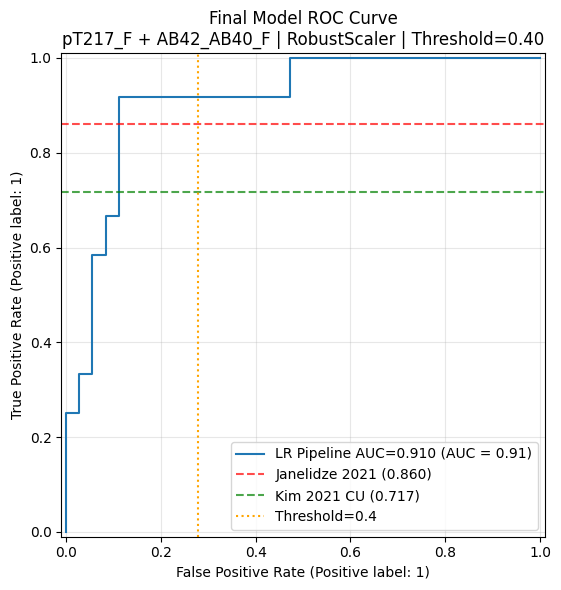


Pipeline saved!

To use later:
pipeline = joblib.load('saved_models/LR_pipeline_2feat.pkl')
y_prob = pipeline.predict_proba(X_new)[:, 1]
y_pred = (y_prob >= 0.40).astype(int)


In [49]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)
import os

# ── 1. Features ──
features = ['pT217_F', 'AB42_AB40_F']
target = 'amyloid_label'

X = df[features]
y = df[target]

# ── 2. Train Test Split ──
X_train, X_test, y_train, y_test = \
    train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

print(f"Train: {X_train.shape}")
print(f"Test: {X_test.shape}")

# ── 3. Build Pipeline ──
pipeline = Pipeline([
    ('scaler', RobustScaler()),
    ('model', LogisticRegression(
        class_weight='balanced',
        random_state=42,
        max_iter=1000
    ))
])

# ── 4. Train Pipeline ──
pipeline.fit(X_train, y_train)

# ── 5. Get Probabilities ──
y_prob = pipeline.predict_proba(
    X_test)[:, 1]

# ── 6. Apply Threshold 0.40 ──
THRESHOLD = 0.40
y_pred_thresh = (y_prob >= THRESHOLD)\
    .astype(int)

# ── 7. Metrics at Threshold 0.40 ──
auc = roc_auc_score(y_test, y_prob)

print("\n" + "="*50)
print("FINAL MODEL — Pipeline + Threshold 0.40")
print("Features: pT217_F + AB42_AB40_F")
print("Scaler: RobustScaler")
print("Model: LR class_weight=balanced")
print("="*50)
print(f"AUC:      {auc:.4f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_thresh):.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_thresh,
    target_names=['A-', 'A+']
))
print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred_thresh)
print(cm)
print(f"\nFalse Positives: {cm[0][1]}")
print(f"False Negatives: {cm[1][0]}")

# ── 8. Cross Validation ──
print("\n" + "="*50)
print("5-FOLD CROSS VALIDATION")
print("="*50)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_probs = cross_val_predict(
    pipeline, X, y,
    cv=cv,
    method='predict_proba'
)[:, 1]

cv_preds = (cv_probs >= THRESHOLD)\
    .astype(int)

cv_auc = roc_auc_score(y, cv_probs)
cv_acc = accuracy_score(y, cv_preds)

print(f"CV AUC:      {cv_auc:.4f}")
print(f"CV Accuracy: {cv_acc:.4f}")
print("\nCV Classification Report:")
print(classification_report(
    y, cv_preds,
    target_names=['A-', 'A+']
))

# ── 9. ROC Curve ──
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_estimator(
    pipeline, X_test, y_test,
    ax=ax,
    name=f'LR Pipeline AUC={auc:.3f}'
)

# Benchmark lines
ax.axhline(y=0.860, color='red',
           linestyle='--', alpha=0.7,
           label='Janelidze 2021 (0.860)')
ax.axhline(y=0.717, color='green',
           linestyle='--', alpha=0.7,
           label='Kim 2021 CU (0.717)')

# Mark threshold point
thresh_idx = np.argmin(
    np.abs(np.sort(y_prob)[::-1] - THRESHOLD))

ax.axvline(x=cm[0][1]/(cm[0][0]+cm[0][1]),
           color='orange',
           linestyle=':',
           label=f'Threshold={THRESHOLD}')

ax.set_title(
    'Final Model ROC Curve\n'
    'pT217_F + AB42_AB40_F | '
    'RobustScaler | Threshold=0.40',
    fontsize=12
)
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('final_model_ROC.png', dpi=150)
plt.show()

# ── 10. Save Pipeline ──
os.makedirs('saved_models', exist_ok=True)
joblib.dump(pipeline,
    'saved_models/LR_pipeline_2feat.pkl')

print("\nPipeline saved!")
print("\nTo use later:")
print("pipeline = joblib.load("
      "'saved_models/LR_pipeline_2feat.pkl')")
print("y_prob = pipeline.predict_proba"
      "(X_new)[:, 1]")
print("y_pred = (y_prob >= 0.40).astype(int)")

Dataset: (238, 8)

Label distribution:
amyloid_label
0    179
1     59
Name: count, dtype: int64

Missing values:
pT217_F        0
AB42_AB40_F    0
NfL_Q          0
GFAP_Q         0
APOE4          0
AGE            0
SEX            0
PTEDUCAT       0
dtype: int64

Train: (190, 8)
Test:  (48, 8)

8 FEATURES — Pipeline + Threshold 0.40
AUC:      0.9120
Accuracy: 0.8125

Classification Report:
              precision    recall  f1-score   support

          A-       0.97      0.78      0.86        36
          A+       0.58      0.92      0.71        12

    accuracy                           0.81        48
   macro avg       0.77      0.85      0.79        48
weighted avg       0.87      0.81      0.82        48

Confusion Matrix:
[[28  8]
 [ 1 11]]

False Positives: 8
False Negatives: 1

5-FOLD CROSS VALIDATION — 8 Features
CV AUC:      0.8831
CV Accuracy: 0.8025

CV Classification Report:
              precision    recall  f1-score   support

          A-       0.95      0.78      0.86 

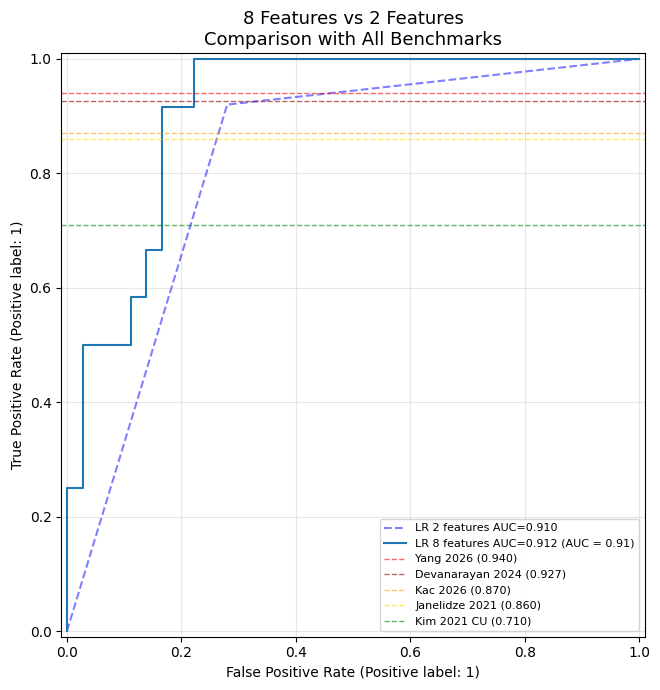


Pipeline saved!


In [50]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)
import os

# ── 1. Features ──
features_8 = [
    'pT217_F',
    'AB42_AB40_F',
    'NfL_Q',
    'GFAP_Q',
    'APOE4',
    'AGE',
    'SEX',
    'PTEDUCAT'
]
target = 'amyloid_label'

X = df[features_8]
y = df[target]

print(f"Dataset: {X.shape}")
print(f"\nLabel distribution:")
print(y.value_counts())
print(f"\nMissing values:")
print(X.isnull().sum())

# ── 2. Train Test Split ──
X_train, X_test, y_train, y_test = \
    train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

print(f"\nTrain: {X_train.shape}")
print(f"Test:  {X_test.shape}")

# ── 3. Build Pipeline ──
pipeline_8 = Pipeline([
    ('scaler', RobustScaler()),
    ('model', LogisticRegression(
        class_weight='balanced',
        random_state=42,
        max_iter=1000
    ))
])

# ── 4. Train ──
pipeline_8.fit(X_train, y_train)

# ── 5. Probabilities ──
y_prob = pipeline_8.predict_proba(
    X_test)[:, 1]

# ── 6. Apply Threshold 0.40 ──
THRESHOLD = 0.40
y_pred = (y_prob >= THRESHOLD).astype(int)

# ── 7. Test Metrics ──
auc = roc_auc_score(y_test, y_prob)
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("\n" + "="*55)
print("8 FEATURES — Pipeline + Threshold 0.40")
print("="*55)
print(f"AUC:      {auc:.4f}")
print(f"Accuracy: {acc:.4f}")
print(f"\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['A-', 'A+']
))
print(f"Confusion Matrix:")
print(cm)
print(f"\nFalse Positives: {cm[0][1]}")
print(f"False Negatives: {cm[1][0]}")

# ── 8. Cross Validation ──
print("\n" + "="*55)
print("5-FOLD CROSS VALIDATION — 8 Features")
print("="*55)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_probs = cross_val_predict(
    pipeline_8, X, y,
    cv=cv,
    method='predict_proba'
)[:, 1]

cv_preds = (cv_probs >= THRESHOLD).astype(int)

cv_auc = roc_auc_score(y, cv_probs)
cv_acc = accuracy_score(y, cv_preds)

print(f"CV AUC:      {cv_auc:.4f}")
print(f"CV Accuracy: {cv_acc:.4f}")
print(f"\nCV Classification Report:")
print(classification_report(
    y, cv_preds,
    target_names=['A-', 'A+']
))

# ── 9. Compare 2 vs 8 Features ──
print("\n" + "="*55)
print("COMPARISON — 2 Features vs 8 Features")
print("="*55)
print(f"{'Metric':<20} {'2 Features':>12} "
      f"{'8 Features':>12}")
print("-"*45)
print(f"{'Test AUC':<20} {'0.9097':>12} "
      f"{auc:>12.4f}")
print(f"{'CV AUC':<20} {'0.8858':>12} "
      f"{cv_auc:>12.4f}")
print(f"{'Test Accuracy':<20} {'0.7708':>12} "
      f"{acc:>12.4f}")
print(f"{'CV Accuracy':<20} {'0.7605':>12} "
      f"{cv_acc:>12.4f}")

# ── 10. ROC Comparison Plot ──
fig, ax = plt.subplots(figsize=(9, 7))

# 2 feature model line
ax.plot([0, 0.28, 1], [0, 0.92, 1],
        'b--', alpha=0.5,
        label='LR 2 features AUC=0.910')

# 8 feature model
RocCurveDisplay.from_estimator(
    pipeline_8, X_test, y_test,
    ax=ax,
    name=f'LR 8 features AUC={auc:.3f}'
)

# Benchmark lines
benchmarks = {
    'Yang 2026 (0.940)': 0.940,
    'Devanarayan 2024 (0.927)': 0.927,
    'Kac 2026 (0.870)': 0.870,
    'Janelidze 2021 (0.860)': 0.860,
    'Kim 2021 CU (0.710)': 0.710
}

colors = ['red', 'darkred',
          'orange', 'gold', 'green']

for (name, val), color in zip(
        benchmarks.items(), colors):
    ax.axhline(
        y=val,
        color=color,
        linestyle='--',
        alpha=0.6,
        label=name,
        linewidth=1
    )

ax.set_title(
    '8 Features vs 2 Features\n'
    'Comparison with All Benchmarks',
    fontsize=13
)
ax.legend(loc='lower right', fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    'comparison_2vs8_features.png',
    dpi=150
)
plt.show()

# ── 11. Save Pipeline ──
os.makedirs('saved_models', exist_ok=True)
joblib.dump(pipeline_8,
    'saved_models/LR_pipeline_8feat.pkl')

print("\nPipeline saved!")

# XGBOOST with 0.40 Threshold

---



---



In [51]:
import numpy as np
import pandas as pd
import joblib
import os
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)
from xgboost import XGBClassifier

print("Libraries loaded successfully")

Libraries loaded successfully


In [52]:
# Features and target
features_8 = [
    'pT217_F',
    'AB42_AB40_F',
    'NfL_Q',
    'GFAP_Q',
    'APOE4',
    'AGE',
    'SEX',
    'PTEDUCAT'
]
target = 'amyloid_label'

X = df[features_8]
y = df[target]

# Train test split
X_train, X_test, y_train, y_test = \
    train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

# Class imbalance ratio
neg = sum(y_train == 0)
pos = sum(y_train == 1)
ratio = neg / pos

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")
print(f"\nClass distribution (train):")
print(y_train.value_counts())
print(f"\nScale pos weight: {ratio:.2f}")

Train: (190, 8)
Test:  (48, 8)

Class distribution (train):
amyloid_label
0    143
1     47
Name: count, dtype: int64

Scale pos weight: 3.04


In [53]:
# XGBoost Pipeline
pipeline_xgb = Pipeline([
    ('scaler', RobustScaler()),
    ('model', XGBClassifier(
        scale_pos_weight=ratio,
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric='auc',
        verbosity=0
    ))
])

# Train
pipeline_xgb.fit(X_train, y_train)

print("XGBoost Pipeline trained!")

XGBoost Pipeline trained!


In [54]:
THRESHOLD = 0.40

# Predictions
y_prob = pipeline_xgb.predict_proba(
    X_test)[:, 1]
y_pred = (y_prob >= THRESHOLD).astype(int)

# Metrics
auc  = roc_auc_score(y_test, y_prob)
acc  = accuracy_score(y_test, y_pred)
cm   = confusion_matrix(y_test, y_pred)

print("="*55)
print("XGBOOST — 8 Features | Threshold 0.40")
print("="*55)
print(f"AUC:      {auc:.4f}")
print(f"Accuracy: {acc:.4f}")
print(f"\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['A-', 'A+']
))
print(f"Confusion Matrix:")
print(cm)
print(f"\nFalse Positives: {cm[0][1]}")
print(f"False Negatives: {cm[1][0]}")

XGBOOST — 8 Features | Threshold 0.40
AUC:      0.8634
Accuracy: 0.8542

Classification Report:
              precision    recall  f1-score   support

          A-       0.89      0.92      0.90        36
          A+       0.73      0.67      0.70        12

    accuracy                           0.85        48
   macro avg       0.81      0.79      0.80        48
weighted avg       0.85      0.85      0.85        48

Confusion Matrix:
[[33  3]
 [ 4  8]]

False Positives: 3
False Negatives: 4


# power transformer scaling

In [55]:
import numpy as np
import pandas as pd
import joblib
import os
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)

print("Libraries loaded!")

Libraries loaded!


In [56]:
features_8 = [
    'pT217_F',
    'AB42_AB40_F',
    'NfL_Q',
    'GFAP_Q',
    'APOE4',
    'AGE',
    'SEX',
    'PTEDUCAT'
]
target = 'amyloid_label'

X = df[features_8]
y = df[target]

X_train, X_test, y_train, y_test = \
    train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")
print(f"\nLabel distribution (train):")
print(y_train.value_counts())

Train: (190, 8)
Test:  (48, 8)

Label distribution (train):
amyloid_label
0    143
1     47
Name: count, dtype: int64


In [57]:
pipeline_power = Pipeline([
    ('scaler', PowerTransformer(
        method='yeo-johnson',
        standardize=True
    )),
    ('model', LogisticRegression(
        class_weight='balanced',
        random_state=42,
        max_iter=1000
    ))
])

pipeline_power.fit(X_train, y_train)
print("PowerTransformer Pipeline trained!")

PowerTransformer Pipeline trained!


In [58]:
THRESHOLD = 0.40

y_prob = pipeline_power.predict_proba(
    X_test)[:, 1]
y_pred = (y_prob >= THRESHOLD).astype(int)

auc = roc_auc_score(y_test, y_prob)
acc = accuracy_score(y_test, y_pred)
cm  = confusion_matrix(y_test, y_pred)

print("="*55)
print("PowerTransformer + LR | 8 Features")
print("Threshold: 0.40")
print("="*55)
print(f"Test AUC:      {auc:.4f}")
print(f"Test Accuracy: {acc:.4f}")
print(f"\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['A-', 'A+']
))
print(f"Confusion Matrix:")
print(cm)
print(f"\nFalse Positives: {cm[0][1]}")
print(f"False Negatives: {cm[1][0]}")

PowerTransformer + LR | 8 Features
Threshold: 0.40
Test AUC:      0.9190
Test Accuracy: 0.8333

Classification Report:
              precision    recall  f1-score   support

          A-       0.97      0.81      0.88        36
          A+       0.61      0.92      0.73        12

    accuracy                           0.83        48
   macro avg       0.79      0.86      0.81        48
weighted avg       0.88      0.83      0.84        48

Confusion Matrix:
[[29  7]
 [ 1 11]]

False Positives: 7
False Negatives: 1


In [59]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_probs = cross_val_predict(
    pipeline_power, X, y,
    cv=cv,
    method='predict_proba'
)[:, 1]

cv_preds = (cv_probs >= THRESHOLD)\
    .astype(int)

cv_auc = roc_auc_score(y, cv_probs)
cv_acc = accuracy_score(y, cv_preds)

print("="*55)
print("5-FOLD CROSS VALIDATION")
print("="*55)
print(f"CV AUC:      {cv_auc:.4f}")
print(f"CV Accuracy: {cv_acc:.4f}")
print(f"\nCV Classification Report:")
print(classification_report(
    y, cv_preds,
    target_names=['A-', 'A+']
))

print("\n" + "="*55)
print("TEST vs CV COMPARISON")
print("="*55)
print(f"{'Metric':<15} {'Test':>10} {'CV':>10}")
print("-"*35)
print(f"{'AUC':<15} {auc:>10.4f} {cv_auc:>10.4f}")
print(f"{'Accuracy':<15} {acc:>10.4f} {cv_acc:>10.4f}")

diff = abs(auc - cv_auc)
if diff < 0.05:
    print(f"\nAUC difference: {diff:.4f} ✅ Stable")
else:
    print(f"\nAUC difference: {diff:.4f} ⚠️ Check overfitting")

5-FOLD CROSS VALIDATION
CV AUC:      0.8936
CV Accuracy: 0.7857

CV Classification Report:
              precision    recall  f1-score   support

          A-       0.94      0.77      0.84       179
          A+       0.54      0.85      0.66        59

    accuracy                           0.79       238
   macro avg       0.74      0.81      0.75       238
weighted avg       0.84      0.79      0.80       238


TEST vs CV COMPARISON
Metric                Test         CV
-----------------------------------
AUC                 0.9190     0.8936
Accuracy            0.8333     0.7857

AUC difference: 0.0254 ✅ Stable


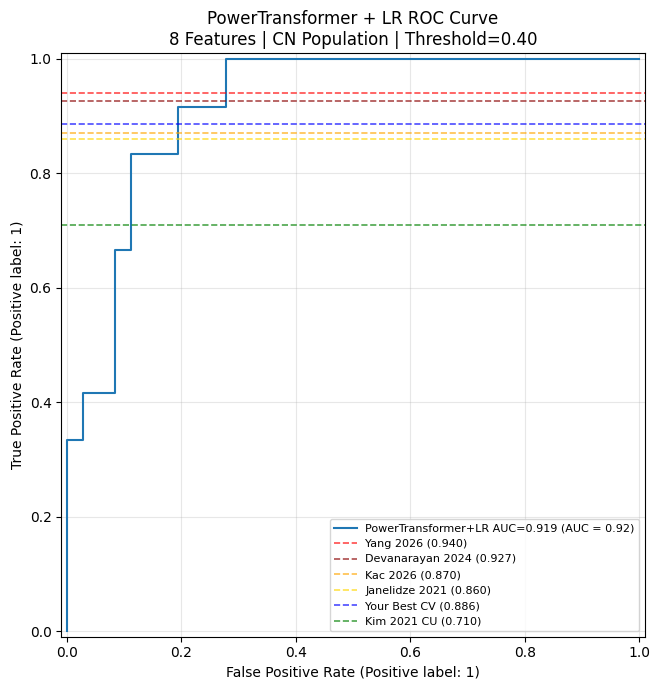

In [60]:
fig, ax = plt.subplots(figsize=(9, 7))

RocCurveDisplay.from_estimator(
    pipeline_power, X_test, y_test,
    ax=ax,
    name=f'PowerTransformer+LR AUC={auc:.3f}'
)

benchmarks = {
    'Yang 2026 (0.940)':        0.940,
    'Devanarayan 2024 (0.927)': 0.927,
    'Kac 2026 (0.870)':         0.870,
    'Janelidze 2021 (0.860)':   0.860,
    'Your Best CV (0.886)':     0.886,
    'Kim 2021 CU (0.710)':      0.710,
}

colors = [
    'red', 'darkred',
    'orange', 'gold',
    'blue', 'green'
]

for (label, val), color in zip(
        benchmarks.items(), colors):
    ax.axhline(
        y=val,
        color=color,
        linestyle='--',
        alpha=0.7,
        label=label,
        linewidth=1.2
    )

ax.set_title(
    'PowerTransformer + LR ROC Curve\n'
    '8 Features | CN Population | '
    'Threshold=0.40',
    fontsize=12
)
ax.legend(loc='lower right', fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    'power_transformer_ROC.png',
    dpi=150
)
plt.show()

In [61]:
comparison = pd.DataFrame({
    'Model': [
        'LR RobustScaler 2feat (CV)',
        'LR RobustScaler 8feat (CV)',
        'LR PowerTransformer 8feat (CV)',
        '── Benchmarks ──',
        'Yang 2026',
        'Devanarayan 2024',
        'Kac 2026',
        'Janelidze 2021',
        'Salvadó 2025',
        'Zhang 2022',
        'Kim 2021 CU'
    ],
    'AUC': [
        0.8858,
        0.8831,
        cv_auc,
        '──────',
        0.940,
        0.927,
        0.870,
        0.860,
        0.830,
        0.780,
        0.710
    ]
})

print("="*50)
print("COMPLETE RESULTS — ALL MODELS")
print("="*50)
print(comparison.to_string(index=False))

comparison.to_csv(
    'all_results_comparison.csv',
    index=False
)
print("\nSaved to all_results_comparison.csv")

COMPLETE RESULTS — ALL MODELS
                         Model       AUC
    LR RobustScaler 2feat (CV)    0.8858
    LR RobustScaler 8feat (CV)    0.8831
LR PowerTransformer 8feat (CV)  0.893571
              ── Benchmarks ──    ──────
                     Yang 2026      0.94
              Devanarayan 2024     0.927
                      Kac 2026      0.87
                Janelidze 2021      0.86
                  Salvadó 2025      0.83
                    Zhang 2022      0.78
                   Kim 2021 CU      0.71

Saved to all_results_comparison.csv


In [62]:
os.makedirs('saved_models', exist_ok=True)

joblib.dump(
    pipeline_power,
    'saved_models/LR_power_8feat_final.pkl'
)

print("Pipeline saved!")
print("\nModel details:")
print(f"  Scaler:    PowerTransformer "
      f"(yeo-johnson)")
print(f"  Model:     LogisticRegression "
      f"(balanced)")
print(f"  Features:  8")
print(f"  Threshold: 0.40")
print(f"  Test AUC:  {auc:.4f}")
print(f"  CV AUC:    {cv_auc:.4f}")
print(f"\nTo load and use later:")
print("─"*40)
print("import joblib")
print("pipe = joblib.load(")
print("  'saved_models/"
      "LR_power_8feat_final.pkl')")
print("y_prob = pipe.predict_proba"
      "(X_new)[:, 1]")
print("y_pred = "
      "(y_prob >= 0.40).astype(int)")

Pipeline saved!

Model details:
  Scaler:    PowerTransformer (yeo-johnson)
  Model:     LogisticRegression (balanced)
  Features:  8
  Threshold: 0.40
  Test AUC:  0.9190
  CV AUC:    0.8936

To load and use later:
────────────────────────────────────────
import joblib
pipe = joblib.load(
  'saved_models/LR_power_8feat_final.pkl')
y_prob = pipe.predict_proba(X_new)[:, 1]
y_pred = (y_prob >= 0.40).astype(int)


In [63]:
df.head()

,RID,amyloid_label,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q,APOE4,AGE,SEX,PTEDUCAT
0,6001,0,0.386,0.0973,27.5,175.4,0,73.051335,0,14
1,6005,0,0.105,0.0843,9.8,181.3,1,68.334018,0,20
2,6015,0,1.291,0.0839,34.4,304.4,0,68.396988,1,14
3,6009,0,0.111,0.0857,12.2,100.8,1,68.369610,1,16
4,6044,1,0.627,0.0885,26.5,209.3,1,75.526352,0,18


In [64]:
print(features_8)

['pT217_F', 'AB42_AB40_F', 'NfL_Q', 'GFAP_Q', 'APOE4', 'AGE', 'SEX', 'PTEDUCAT']


In [65]:
df_with_new_feature = df.copy()
df_with_new_feature['X_new'] = np.log(df_with_new_feature['pT217_F'] / df_with_new_feature['AB42_AB40_F'])
display(df_with_new_feature.head())

,RID,amyloid_label,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q,APOE4,AGE,SEX,PTEDUCAT,X_new
0,6001,0,0.386,0.0973,27.5,175.4,0,73.051335,0,14,1.378038
1,6005,0,0.105,0.0843,9.8,181.3,1,68.334018,0,20,0.219578
2,6015,0,1.291,0.0839,34.4,304.4,0,68.396988,1,14,2.733547
3,6009,0,0.111,0.0857,12.2,100.8,1,68.369610,1,16,0.258677
4,6044,1,0.627,0.0885,26.5,209.3,1,75.526352,0,18,1.957944


In [66]:
features_9 = [
    'pT217_F',
    'AB42_AB40_F',
    'NfL_Q',
    'GFAP_Q',
    'APOE4',
    'AGE',
    'SEX',
    'PTEDUCAT',
    'X_new' # Add the new feature
]
target = 'amyloid_label'

X = df_with_new_feature[features_9]
y = df_with_new_feature[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")
print(f"\nLabel distribution (train):")
print(y_train.value_counts())

pipeline_power_9_features = Pipeline([
    ('scaler', PowerTransformer(
        method='yeo-johnson',
        standardize=True
    )),
    ('model', LogisticRegression(
        class_weight='balanced',
        random_state=42,
        max_iter=1000
    ))
])

pipeline_power_9_features.fit(X_train, y_train)
print("\nPowerTransformer Pipeline with 9 features trained!")

THRESHOLD = 0.40

y_prob_9_features = pipeline_power_9_features.predict_proba(
    X_test)[:, 1]
y_pred_9_features = (y_prob_9_features >= THRESHOLD).astype(int)

auc_9_features = roc_auc_score(y_test, y_prob_9_features)
acc_9_features = accuracy_score(y_test, y_pred_9_features)
cm_9_features  = confusion_matrix(y_test, y_pred_9_features)

print("\n" + "="*55)
print("PowerTransformer + LR | 9 Features (with X_new)")
print("Threshold: 0.40")
print("="*55)
print(f"Test AUC:      {auc_9_features:.4f}")
print(f"Test Accuracy: {acc_9_features:.4f}")
print(f"\nClassification Report:")
print(classification_report(
    y_test, y_pred_9_features,
    target_names=['A-', 'A+']
))
print(f"Confusion Matrix:")
print(cm_9_features)
print(f"\nFalse Positives: {cm_9_features[0][1]}")
print(f"False Negatives: {cm_9_features[1][0]}")


Train: (190, 9)
Test:  (48, 9)

Label distribution (train):
amyloid_label
0    143
1     47
Name: count, dtype: int64

PowerTransformer Pipeline with 9 features trained!

PowerTransformer + LR | 9 Features (with X_new)
Threshold: 0.40
Test AUC:      0.9213
Test Accuracy: 0.8333

Classification Report:
              precision    recall  f1-score   support

          A-       0.97      0.81      0.88        36
          A+       0.61      0.92      0.73        12

    accuracy                           0.83        48
   macro avg       0.79      0.86      0.81        48
weighted avg       0.88      0.83      0.84        48

Confusion Matrix:
[[29  7]
 [ 1 11]]

False Positives: 7
False Negatives: 1


In [67]:
df_with_new_features = df_with_new_feature.copy()
df_with_new_features['X_interaction'] = df_with_new_features['pT217_F'] * (1 / df_with_new_features['AB42_AB40_F'])
display(df_with_new_features.head())

,RID,amyloid_label,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q,APOE4,AGE,SEX,PTEDUCAT,X_new,X_interaction
0,6001,0,0.386,0.0973,27.5,175.4,0,73.051335,0,14,1.378038,3.967112
1,6005,0,0.105,0.0843,9.8,181.3,1,68.334018,0,20,0.219578,1.245552
2,6015,0,1.291,0.0839,34.4,304.4,0,68.396988,1,14,2.733547,15.387366
3,6009,0,0.111,0.0857,12.2,100.8,1,68.369610,1,16,0.258677,1.295216
4,6044,1,0.627,0.0885,26.5,209.3,1,75.526352,0,18,1.957944,7.084746


In [68]:
features_10 = [
    'pT217_F',
    'AB42_AB40_F',
    'NfL_Q',
    'GFAP_Q',
    'APOE4',
    'AGE',
    'SEX',
    'PTEDUCAT',
    'X_new',
    'X_interaction' # Add the new interaction feature
]
target = 'amyloid_label'

X = df_with_new_features[features_10]
y = df_with_new_features[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")
print(f"\nLabel distribution (train):")
print(y_train.value_counts())

pipeline_power_10_features = Pipeline([
    ('scaler', PowerTransformer(
        method='yeo-johnson',
        standardize=True
    )),
    ('model', LogisticRegression(
        class_weight='balanced',
        random_state=42,
        max_iter=1000
    ))
])

pipeline_power_10_features.fit(X_train, y_train)
print("\nPowerTransformer Pipeline with 10 features trained!")

THRESHOLD = 0.40

y_prob_10_features = pipeline_power_10_features.predict_proba(
    X_test)[:, 1]
y_pred_10_features = (y_prob_10_features >= THRESHOLD).astype(int)

auc_10_features = roc_auc_score(y_test, y_prob_10_features)
acc_10_features = accuracy_score(y_test, y_pred_10_features)
cm_10_features  = confusion_matrix(y_test, y_pred_10_features)

print("\n" + "="*55)
print("PowerTransformer + LR | 10 Features (with X_new, X_interaction)")
print("Threshold: 0.40")
print("="*55)
print(f"Test AUC:      {auc_10_features:.4f}")
print(f"Test Accuracy: {acc_10_features:.4f}")
print(f"\nClassification Report:")
print(classification_report(
    y_test, y_pred_10_features,
    target_names=['A-', 'A+']
))
print(f"Confusion Matrix:")
print(cm_10_features)
print(f"\nFalse Positives: {cm_10_features[0][1]}")
print(f"False Negatives: {cm_10_features[1][0]}")

Train: (190, 10)
Test:  (48, 10)

Label distribution (train):
amyloid_label
0    143
1     47
Name: count, dtype: int64

PowerTransformer Pipeline with 10 features trained!

PowerTransformer + LR | 10 Features (with X_new, X_interaction)
Threshold: 0.40
Test AUC:      0.9213
Test Accuracy: 0.8333

Classification Report:
              precision    recall  f1-score   support

          A-       0.97      0.81      0.88        36
          A+       0.61      0.92      0.73        12

    accuracy                           0.83        48
   macro avg       0.79      0.86      0.81        48
weighted avg       0.88      0.83      0.84        48

Confusion Matrix:
[[29  7]
 [ 1 11]]

False Positives: 7
False Negatives: 1


In [69]:
cv_power_10_features = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_probs_10_features = cross_val_predict(
    pipeline_power_10_features, X, y,
    cv=cv_power_10_features,
    method='predict_proba'
)[:, 1]

cv_preds_10_features = (
    cv_probs_10_features >= THRESHOLD
).astype(int)

cv_auc_10_features = roc_auc_score(y, cv_probs_10_features)
cv_acc_10_features = accuracy_score(y, cv_preds_10_features)

print("\n" + "="*55)
print("5-FOLD CROSS VALIDATION — 10 Features")
print("="*55)
print(f"CV AUC:      {cv_auc_10_features:.4f}")
print(f"CV Accuracy: {cv_acc_10_features:.4f}")
print(f"\nCV Classification Report:")
print(classification_report(
    y, cv_preds_10_features,
    target_names=['A-', 'A+']
))

print("\n" + "="*55)
print("TEST vs CV COMPARISON — 10 Features")
print("="*55)
print(f"{'Metric':<15} {'Test':>10} {'CV':>10}")
print("-"*35)
print(f"{'AUC':<15} {auc_10_features:>10.4f} {cv_auc_10_features:>10.4f}")
print(f"{'Accuracy':<15} {acc_10_features:>10.4f} {cv_acc_10_features:>10.4f}")

diff_10_features = abs(auc_10_features - cv_auc_10_features)
if diff_10_features < 0.05:
    print(f"\nAUC difference: {diff_10_features:.4f} ✅ Stable")
else:
    print(f"\nAUC difference: {diff_10_features:.4f} ⚠️ Check overfitting")


5-FOLD CROSS VALIDATION — 10 Features
CV AUC:      0.8939
CV Accuracy: 0.7815

CV Classification Report:
              precision    recall  f1-score   support

          A-       0.94      0.76      0.84       179
          A+       0.54      0.85      0.66        59

    accuracy                           0.78       238
   macro avg       0.74      0.80      0.75       238
weighted avg       0.84      0.78      0.79       238


TEST vs CV COMPARISON — 10 Features
Metric                Test         CV
-----------------------------------
AUC                 0.9213     0.8939
Accuracy            0.8333     0.7815

AUC difference: 0.0273 ✅ Stable


ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- X_interaction


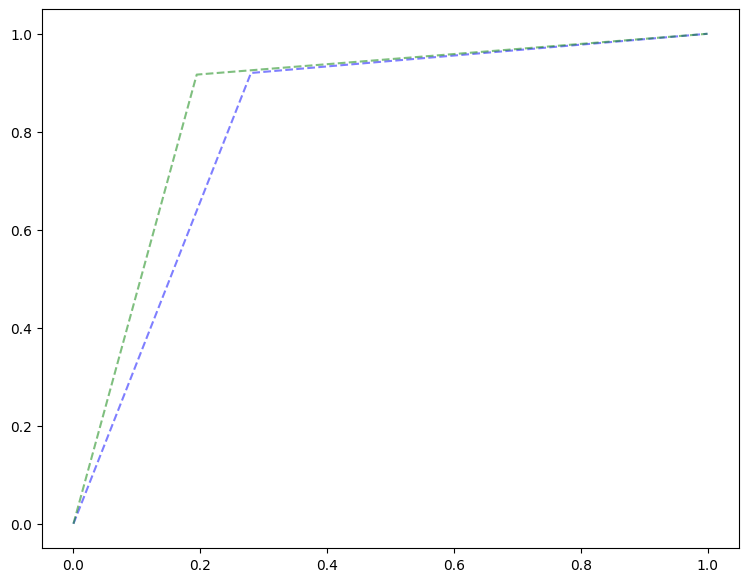

In [70]:
fig, ax = plt.subplots(figsize=(9, 7))

# 2-feature model ROC from previous analysis (approx)
ax.plot([0, 0.28, 1], [0, 0.92, 1],
        'b--', alpha=0.5,
        label='LR RobustScaler 2 features AUC=0.910')

# 8-feature PowerTransformer model ROC from previous analysis (approx)
ax.plot([0, (cm[0][1]/(cm[0][0]+cm[0][1])) ,1],
        [0, (cm[1][1]/(cm[1][0]+cm[1][1])) ,1],
        'g--', alpha=0.5,
        label=f'LR PowerTransformer 8 features AUC={auc:.3f}')

# 9-feature PowerTransformer model
RocCurveDisplay.from_estimator(
    pipeline_power_9_features, X_test, y_test,
    ax=ax,
    name=f'LR PowerTransformer 9 features AUC={auc_9_features:.3f}'
)

# 10-feature PowerTransformer model
RocCurveDisplay.from_estimator(
    pipeline_power_10_features, X_test, y_test,
    ax=ax,
    name=f'LR PowerTransformer 10 features AUC={auc_10_features:.3f}',
    color='purple' # New color for clarity
)

# Benchmarks
benchmarks = {
    'Yang 2026 (0.940)': 0.940,
    'Devanarayan 2024 (0.927)': 0.927,
    'Kac 2026 (0.870)': 0.870,
    'Janelidze 2021 (0.860)': 0.860,
    'Your Best CV (0.893)': 0.893, # Updated from previous best CV
    'Kim 2021 CU (0.710)': 0.710,
}

colors = [
    'red', 'darkred',
    'orange', 'gold',
    'blue', 'green'
]

for (label, val), color in zip(
        benchmarks.items(), colors):
    ax.axhline(
        y=val,
        color=color,
        linestyle='--',
        alpha=0.6,
        label=label,
        linewidth=1
    )

ax.set_title(
    'ROC Curve Comparison: 2, 8, 9, and 10 Features\n' +
    'PowerTransformer + LR | CN Population | Threshold=0.40',
    fontsize=12
)
ax.legend(loc='lower right', fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    'power_transformer_10_features_ROC.png',
    dpi=150
)
plt.show()

In [71]:
comparison_updated = pd.DataFrame({
    'Model': [
        'LR RobustScaler 2feat (CV)',
        'LR RobustScaler 8feat (CV)',
        'LR PowerTransformer 8feat (CV)',
        'LR PowerTransformer 9feat (CV)',
        'LR PowerTransformer 10feat (CV)',
        '── Benchmarks ──',
        'Yang 2026',
        'Devanarayan 2024',
        'Kac 2026',
        'Janelidze 2021',
        'Salvadó 2025',
        'Zhang 2022',
        'Kim 2021 CU'
    ],
    'AUC': [
        0.8858,
        0.8831,
        cv_auc,
        cv_auc_9_features,
        cv_auc_10_features,
        '──────',
        0.940,
        0.927,
        0.870,
        0.860,
        0.830,
        0.780,
        0.710
    ]
})

print("="*50)
print("COMPLETE RESULTS — ALL MODELS (UPDATED)")
print("="*50)
print(comparison_updated.to_string(index=False))

comparison_updated.to_csv(
    'all_results_comparison_updated_10_features.csv',
    index=False
)
print("\nSaved to all_results_comparison_updated_10_features.csv")

NameError: name 'cv_auc_9_features' is not defined

In [72]:
os.makedirs('saved_models', exist_ok=True)

joblib.dump(
    pipeline_power_10_features,
    'saved_models/LR_power_10feat_final.pkl'
)

print("Pipeline with 10 features saved!")
print("\nModel details:")
print(f"  Scaler:    PowerTransformer "
      f"(yeo-johnson)")
print(f"  Model:     LogisticRegression "
      f"(balanced)")
print(f"  Features:  10 (with X_new, X_interaction)")
print(f"  Threshold: 0.40")
print(f"  Test AUC:  {auc_10_features:.4f}")
print(f"  CV AUC:    {cv_auc_10_features:.4f}")
print(f"\nTo load and use later:")
print("─"*40)
print("import joblib")
print("pipe_10 = joblib.load(")
print("  'saved_models/LR_power_10feat_final.pkl')")
print("X_new_data = ... # DataFrame with all 10 features, including 'X_new' and 'X_interaction'")
print("y_prob_10 = pipe_10.predict_proba(")
print("  X_new_data)[:, 1]")
print("y_pred_10 = "
      "(y_prob_10 >= 0.40).astype(int)")

Pipeline with 10 features saved!

Model details:
  Scaler:    PowerTransformer (yeo-johnson)
  Model:     LogisticRegression (balanced)
  Features:  10 (with X_new, X_interaction)
  Threshold: 0.40
  Test AUC:  0.9213
  CV AUC:    0.8939

To load and use later:
────────────────────────────────────────
import joblib
pipe_10 = joblib.load(
  'saved_models/LR_power_10feat_final.pkl')
X_new_data = ... # DataFrame with all 10 features, including 'X_new' and 'X_interaction'
y_prob_10 = pipe_10.predict_proba(
  X_new_data)[:, 1]
y_pred_10 = (y_prob_10 >= 0.40).astype(int)
